# Лабораторная работа №4. Логистическая регрессия

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

import helpers as h
import importlib
from datetime import datetime
importlib.reload(h)
print(f"Модуль обновлён в {datetime.now()}")

import warnings
warnings.filterwarnings("ignore")

Модуль обновлён в 2026-10-16 22:35:54.298194


In [2]:
def graph_setup():
    sns.set_style("whitegrid")
    sns.set_context("notebook", font_scale=1.2)
    plt.rcParams['figure.figsize'] = [8, 6]
    plt.rcParams['figure.dpi'] = 100

graph_setup()

## Решение

In [3]:
data = np.loadtxt("ex2data1.txt", delimiter=",")
X_init = data[:, :(-1)]
X, mean, std = h.normalize(X_init)
y = data[:, -1]
neg_indices = np.where(y == 0)[0]
pos_indices = np.where(y == 1)[0]
X_neg = X[neg_indices]
X_pos = X[pos_indices]

In [4]:
X_test_init = [(501, 500)]
X_test, _, _  = h.normalize(X_test_init, mean, std)
X_test

array([[22.98004596, 22.92722639]])

In [5]:
%%time
epochs = 10_000
alpha = 0.01

clf_linear = h.CustomClassifier("linear")
clf_linear.fit(X, y, alpha=alpha, epochs=epochs)
print(f"Линейная модель; accuracy: {h.accuracy(y, clf_linear.predict(X)):.2f}")

clf_parabolex = h.CustomClassifier("parabolex")
clf_parabolex.fit(X, y, alpha=alpha, epochs=epochs)
print(f"Параболлическая кривая по X; accuracy: {h.accuracy(y, clf_parabolex.predict(X)):.2f}")

clf_paraboley = h.CustomClassifier("paraboley")
clf_paraboley.fit(X, y, alpha=alpha, epochs=epochs)
print(f"Параболлическая кривая по Y; accuracy: {h.accuracy(y, clf_paraboley.predict(X)):.2f}")

clf_hyperbole = h.CustomClassifier("hyperbole")
clf_hyperbole.fit(X, y, alpha=alpha, epochs=epochs)
print(f"Гипрболическая кривая; accuracy: {h.accuracy(y, clf_hyperbole.predict(X)):.2f}")

clf_ellipse = h.CustomClassifier("ellipse")
clf_ellipse.fit(X, y, alpha=alpha, epochs=epochs)
print(f"Эллиптическая кривая; accuracy: {h.accuracy(y, clf_ellipse.predict(X)):.2f}")


Линейная модель; accuracy: 0.89
Параболлическая кривая по X; accuracy: 0.98
Параболлическая кривая по Y; accuracy: 0.95
Гипрболическая кривая; accuracy: 0.96
Эллиптическая кривая; accuracy: 0.99
CPU times: total: 1.61 s
Wall time: 1.63 s


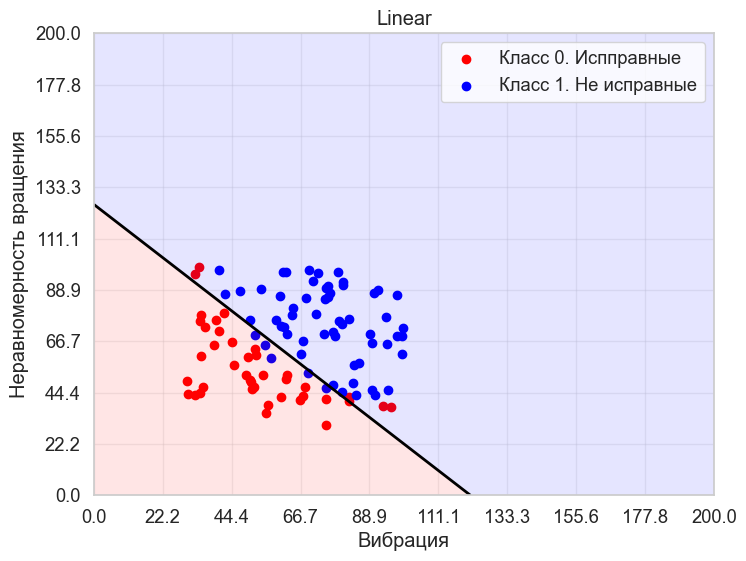

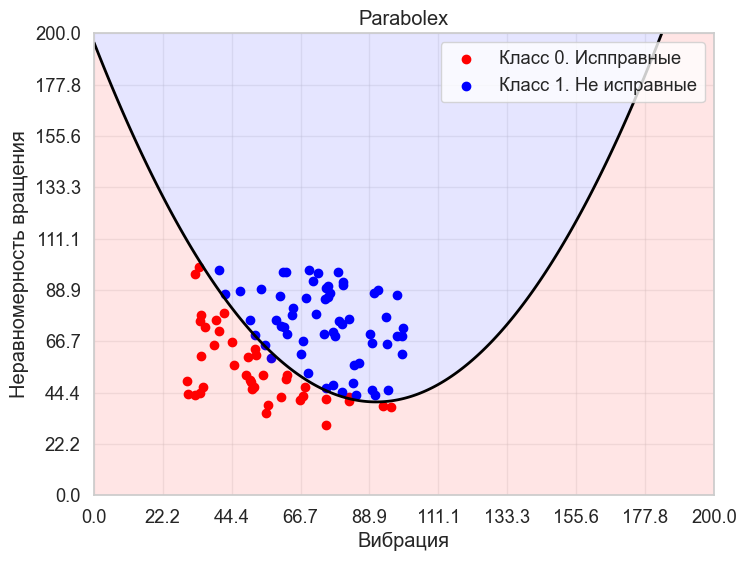

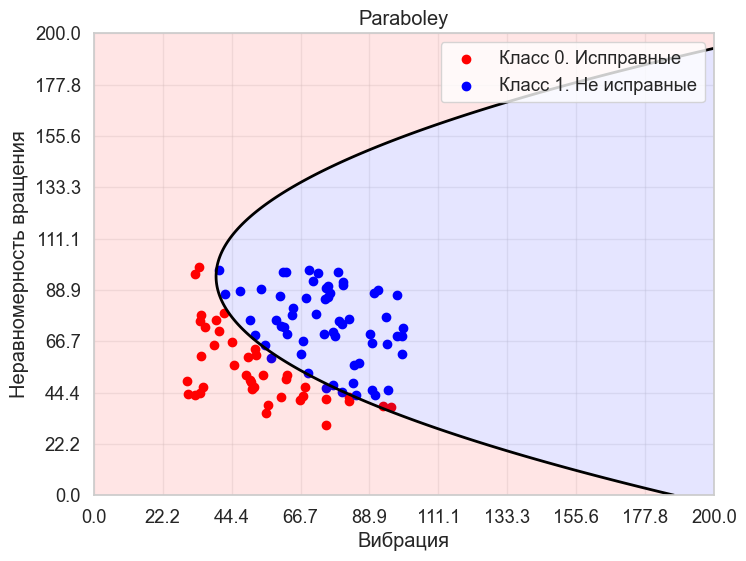

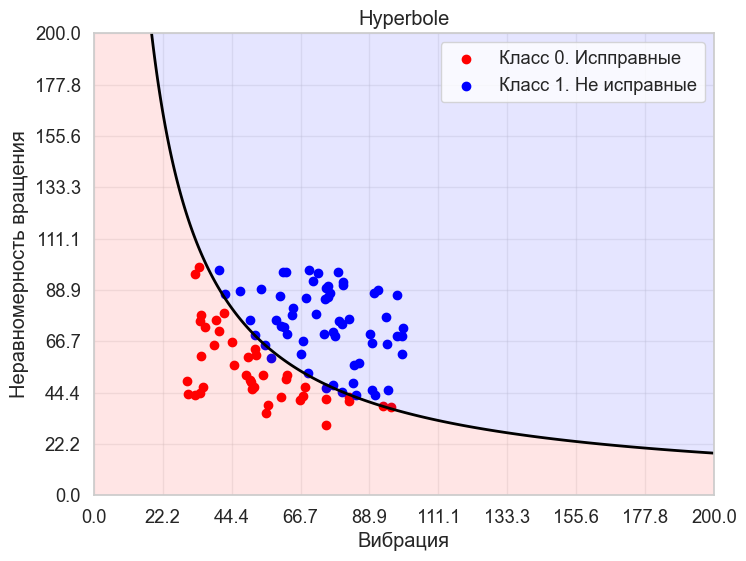

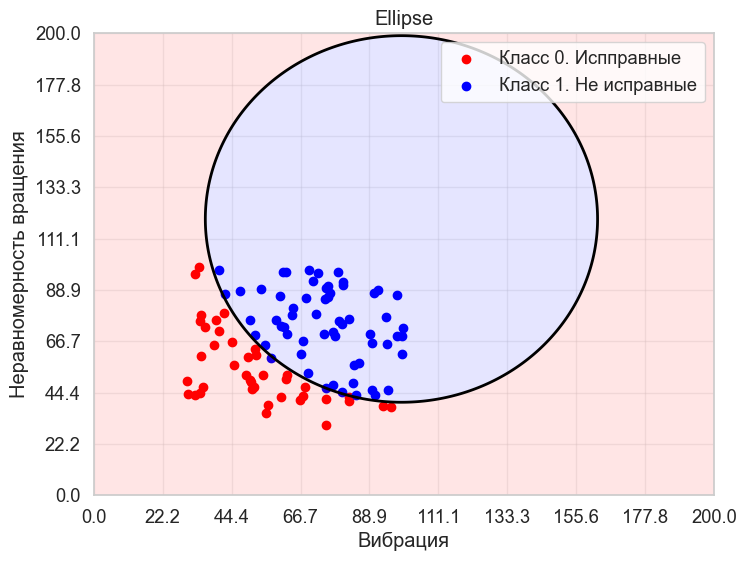

In [6]:
classifiers = clf_linear, clf_parabolex, clf_paraboley, clf_hyperbole, clf_ellipse
names = ["linear", "parabolex", "paraboley", "hyperbole", "ellipse"]
h.plotLines(X_neg, X_pos, classifiers, names, mean, std)

Предсказание линейной модели, класс: 1


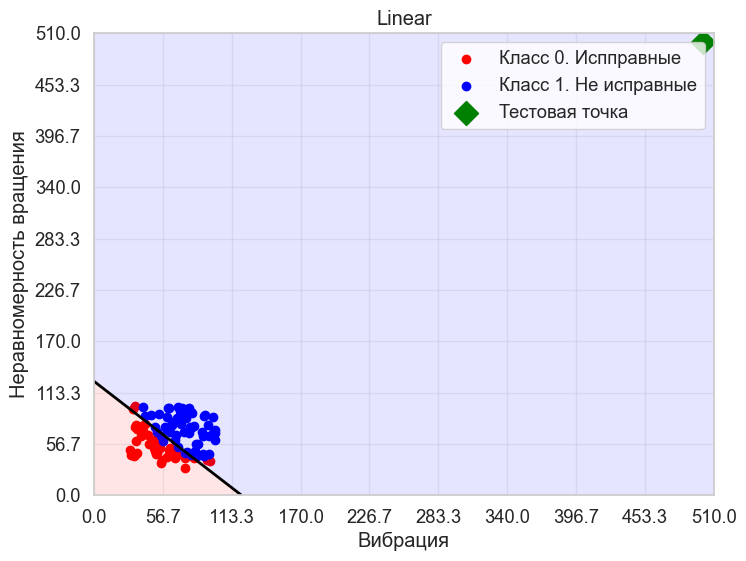

Предсказание параболлической модели X, класс: 0


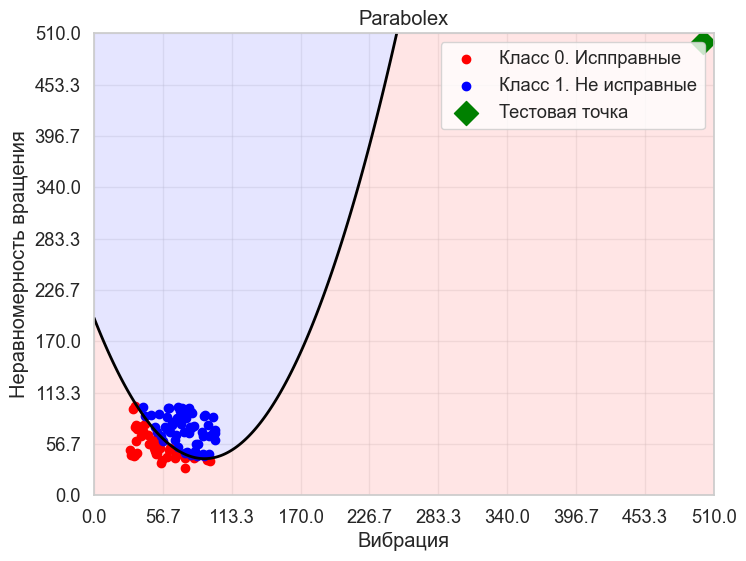

Предсказание параболической модели Y, класс: 0


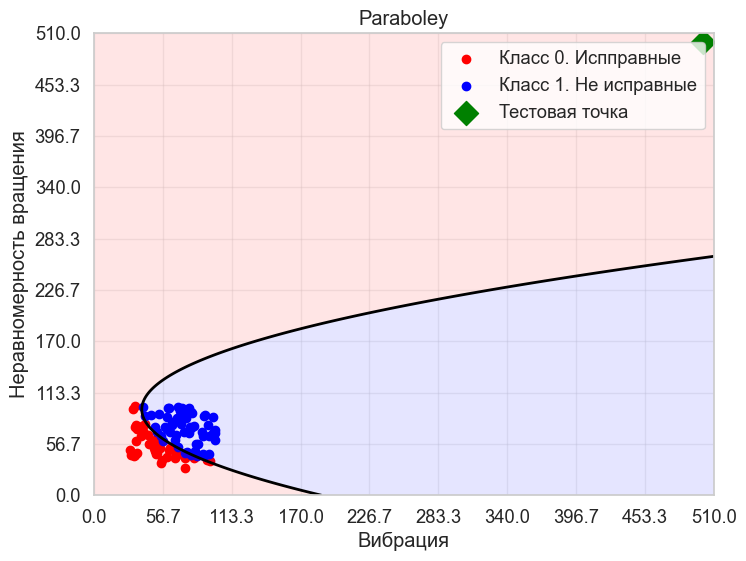

Предсказание гиперболической модели, класс: 1


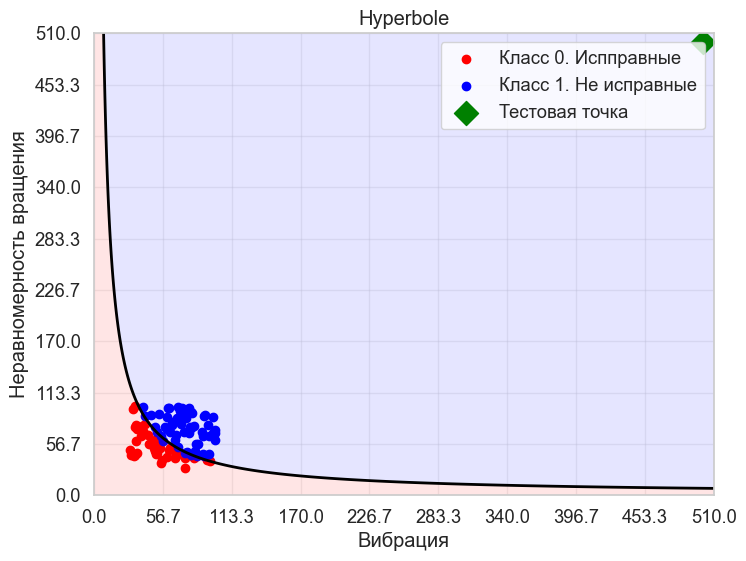

Предсказание эллиптической модели, класс: 0


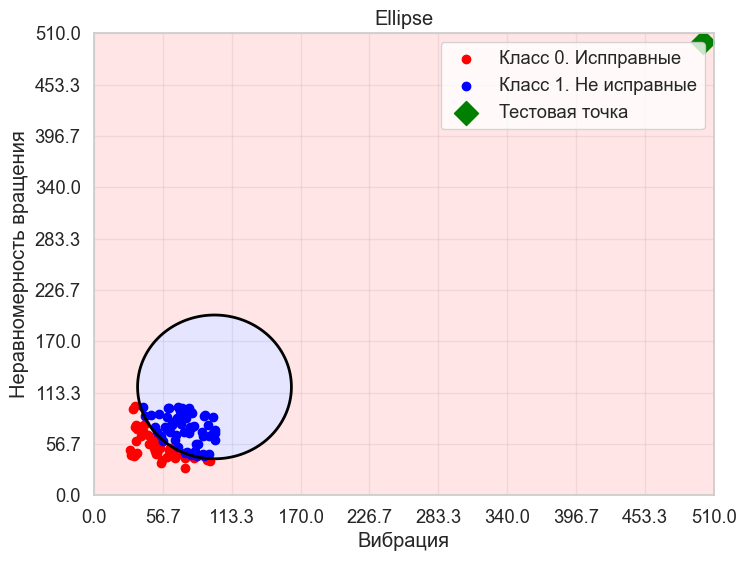

In [7]:
classifiers = clf_linear, clf_parabolex, clf_paraboley, clf_hyperbole, clf_ellipse
names = ["linear", "parabolex", "paraboley", "hyperbole", "ellipse"]
h.plotLines(X_neg, X_pos, classifiers, names, mean, std, left=0, right=510, plot_test=True, X_test=X_test)

In [9]:
h.save_model(clf_ellipse, filename="clf_ellipse.pkl")
h.predict_user_data("clf_ellipse.pkl", "user_data.txt", "predictions.txt", mean, std)

Предсказания успешно записаны в 'predictions.txt'
